In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Draw maps of specific basins or LMEs, based on masks

In [19]:
import esm4ppe
import cartopy.crs as ccrs
import cartopy
import matplotlib.pyplot as plt

In [20]:
variable,frequency='intpp','monthly'

In [21]:
es = esm4ppe.esm4ppeObj(variable,frequency).add_control().climatology()

Opening static... static opened.
Ensemble present in zarr store... opening... ensemble opened.
control opened.
Opening climatology... climatology opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [22]:
masks = esm4ppe.masks.get_masks('LME',es.static)

In [40]:
region = 'Benguela Current'
ds = es.control.where(masks[region]==1,drop=True)
static = es.static.sel({"xh":ds["xh"],"yh":ds["yh"]})

In [41]:
# get boundaries of region
buffer = 0 # set a buffer
lons,lats = (
    [static["geolon"].min().values-buffer,
     static["geolon"].max().values+buffer],
    [static["geolat"].min().values-buffer,
     static["geolat"].max().values+buffer]
)

In [42]:
X = static["geolon"].values
Y = static["geolat"].values
Z = ds[variable].max("month")

In [43]:
import matplotlib.path as mpath
import numpy as np
def create_rectanglepathfromlonlatcorners(lons,lats,resolution=20):
    path = mpath.Path(
        list(zip(np.linspace(lons[0],lons[1], resolution), np.full (resolution, lats[1]))) + \
        list(zip(np.full (resolution, lons[1]), np.linspace(lats[1], lats[0], resolution))) + \
        list(zip(np.linspace(lons[1], lons[0], resolution), np.full (resolution, lats[0]))) + \
        list(zip(np.full (resolution, lons[0]), np.linspace(lats[0], lats[1], resolution)))
    )
    return path

In [44]:
path = create_rectanglepathfromlonlatcorners(lons,lats,20)

Text(0.5, 1.0, 'Benguela Current')

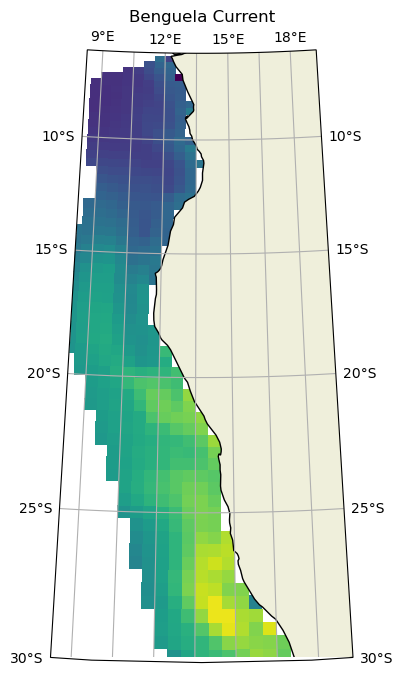

In [46]:
proj = ccrs.LambertConformal(central_longitude=np.mean(lons), central_latitude=np.mean(lats))
fig, ax = plt.subplots(figsize=(12, 8),
                       subplot_kw={'projection':proj})
ax.pcolormesh(X,Y,Z,transform=ccrs.PlateCarree())
ax.set_boundary(path,transform=ccrs.PlateCarree())
ax.add_feature(cartopy.feature.LAND, zorder=1, edgecolor='k')
ax.gridlines(
    draw_labels=True, rotate_labels=False,
    x_inline=False, y_inline=False,
)
ax.set_title(region)

Data variables:
    Baltic Sea                                (xh, yh) bool False ... False
    Sea of Okhotsk                            (xh, yh) bool ...
    North Sea                                 (xh, yh) bool ...
    Gulf of Alaska                            (xh, yh) bool ...
    Labrador - Newfoundland                   (xh, yh) bool ...
    Celtic-Biscay Shelf                       (xh, yh) bool ...
    Sea of Japan                              (xh, yh) bool ...
    Oyashio Current                           (xh, yh) bool ...
    Scotian Shelf                             (xh, yh) bool ...
    California Current                        (xh, yh) bool False ... False
    Black Sea                                 (xh, yh) bool ...
    Northeast U.S. Continental Shelf          (xh, yh) bool ...
    Mediterranean Sea                         (xh, yh) bool ...
    Iberian Coastal                           (xh, yh) bool ...
    Kuroshio Current                          (xh, yh) bool ...
